# Development OOF comparison
The CatBoost model and its feature representation were selected using K20 training folds. Permutation bars show mean accuracy decrease; error bars are sample SD of the three fold-level means. The confusion matrix pools the 8,400 out-of-fold predictions. All values are exploratory.

findfont: Failed to find font weight normal for Helvetica, now using medium.


findfont: Font family ['serif'] not found. Falling back to Helvetica.


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Failed to find font weight normal for Helvetica, now using medium.


findfont: Failed to find font weight normal for Helvetica, now using medium.


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


... (31 outputs left out)

findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


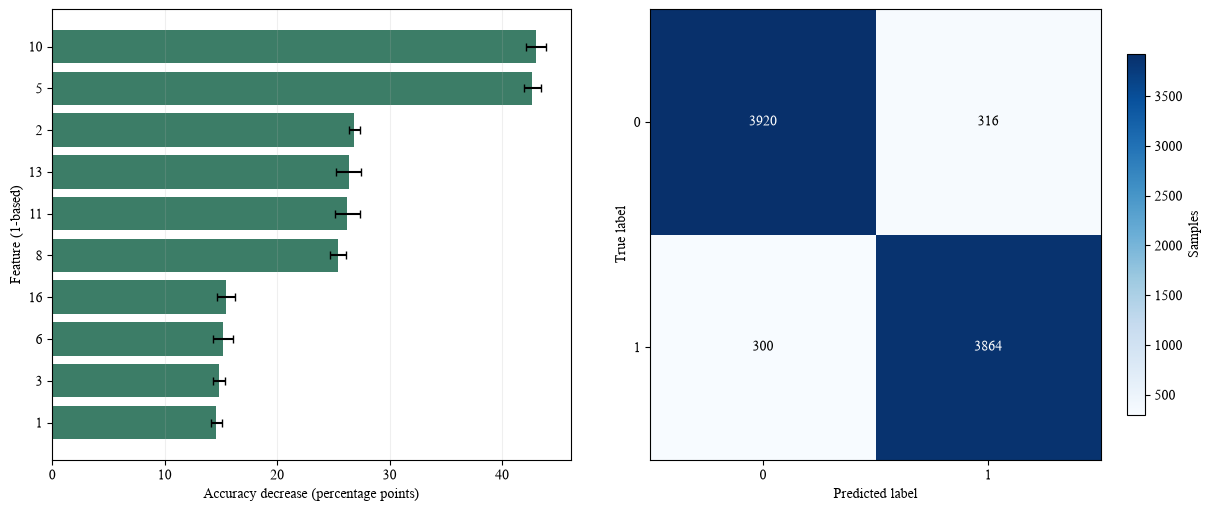

In [1]:
import csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().resolve()
if root.name == 'B_Traditional_ML': root = root.parent
out = root / 'B_Traditional_ML' / 'results' / 'model_analysis'
with (out / 'tuned_catboost_permutation.csv').open(encoding='utf-8', newline='') as f: perm = list(csv.DictReader(f))
with (out / 'comparison' / 'oof_metrics.csv').open(encoding='utf-8', newline='') as f: metrics = list(csv.DictReader(f))
cm = np.array(json.loads(next(r for r in metrics if r['method'] == 'catboost')['pooled_confusion_matrix']))
fold_means = np.array([[np.mean([float(r['accuracy_drop']) for r in perm if int(r['feature_one_based']) == feature and int(r['fold']) == fold]) for fold in range(3)] for feature in range(1, 21)])
means, sd = 100 * fold_means.mean(axis=1), 100 * fold_means.std(axis=1, ddof=1)
order = np.argsort(means)[-10:]
plt.rcParams.update({'pdf.use14corefonts': True, 'font.family': 'serif', 'font.serif': ['Times New Roman']})
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].barh(np.arange(10), means[order], xerr=sd[order], capsize=3, color='#3c7d67')
axes[0].set_yticks(np.arange(10), [str(x + 1) for x in order])
axes[0].set(xlabel='Accuracy decrease (percentage points)', ylabel='Feature (1-based)')
axes[0].grid(axis='x', alpha=.2)
im = axes[1].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2): axes[1].text(j, i, f'{cm[i,j]}', ha='center', va='center', color='white' if cm[i,j] > cm.max()/2 else 'black')
axes[1].set(xticks=[0,1], yticks=[0,1], xticklabels=['0','1'], yticklabels=['0','1'], xlabel='Predicted label', ylabel='True label')
fig.colorbar(im, ax=axes[1], shrink=.8, label='Samples')
(out / 'figures').mkdir(exist_ok=True)
fig.savefig(out / 'figures' / 'catboost_analysis.png', dpi=180)
fig.savefig(out / 'figures' / 'catboost_analysis.pdf')
plt.show()
